# 🎬 Netflix Content Analytics Dashboard

## Project Overview
This project analyzes Netflix's Movies and TV Shows dataset to understand content distribution, genre popularity, release year trends, ratings, duration patterns, and geographic availability.

## Business Problem
Netflix needs data-driven insights to:
- Understand content distribution across Movies and TV Shows.
- Identify the most popular genres.
- Analyze release year trends.
- Study duration patterns.
- Understand rating distribution.
- Analyze country-wise content availability.

## Objectives
- Perform Data Cleaning.
- Handle Missing Values.
- Remove Duplicates.
- Validate Data Types.
- Perform Exploratory Data Analysis (EDA).
- Create 10+ Professional Visualizations.
- Build an Interactive Dashboard.
- Generate Business Insights and Recommendations.

In [13]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

import warnings
warnings.filterwarnings("ignore")


%matplotlib inline

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

print("✅ Libraries Imported Successfully")

✅ Libraries Imported Successfully


In [14]:
from google.colab import files
uploaded = files.upload()

Saving netflix_titles.csv to netflix_titles (1).csv


In [15]:
# Load Dataset

df = pd.read_csv("netflix_titles.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [16]:
# Display First 5 Rows

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [17]:
# Number of Rows and Columns

print("Dataset Shape:", df.shape)

rows, columns = df.shape

print("Number of Rows :", rows)
print("Number of Columns :", columns)

Dataset Shape: (8807, 12)
Number of Rows : 8807
Number of Columns : 12


In [18]:
# Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [19]:
# Display Column Names

df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [20]:
# Statistical Summary

df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8804,4528,7692,748,1767,NaN,17,220,514,8775
top,s8807,Movie,Feb-09,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,2,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [21]:
# Missing Values

missing_values = df.isnull().sum()

missing_values

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [22]:
# Missing Value Percentage

missing_percent = (df.isnull().sum()/len(df))*100

missing_percent.sort_values(ascending=False)

,0
director,29.908028
country,9.435676
cast,9.367549
date_added,0.113546
rating,0.045418
duration,0.034064
show_id,0.000000
type,0.000000
title,0.000000
release_year,0.000000


In [23]:
# Duplicate Records

duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 0


In [24]:
# Data Types

df.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


## Initial Observations

After exploring the dataset:

- Dataset loaded successfully.
- Dataset contains Movies and TV Shows.
- Several columns contain missing values.
- Some columns require data type conversion.
- Duplicate records need to be checked.
- Further data cleaning is required before analysis.

# 🧹 Data Cleaning

Data cleaning is an essential step before analysis. In this phase, we:

- Identify missing values.
- Handle missing data.
- Remove duplicate records.
- Validate data types.
- Convert columns to appropriate formats.
- Create new features for analysis.
- Save the cleaned dataset for further analysis.

In [25]:
# ==========================================
# Missing Values Analysis
# ==========================================

missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})

missing.sort_values("Missing Values", ascending=False)

,Missing Values,Percentage
director,2634,29.908028
country,831,9.435676
cast,825,9.367549
date_added,10,0.113546
rating,4,0.045418
duration,3,0.034064
show_id,0,0.000000
type,0,0.000000
title,0,0.000000
release_year,0,0.000000


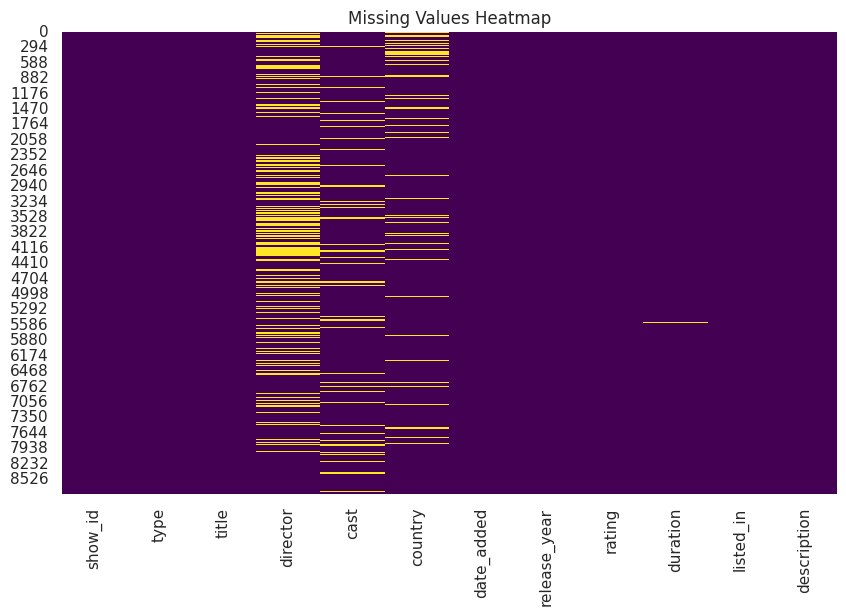

In [26]:
plt.figure(figsize=(10,6))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap="viridis")

plt.title("Missing Values Heatmap")
plt.show()

In [27]:
# Fill Missing Values

df["director"] = df["director"].fillna("Unknown")

df["cast"] = df["cast"].fillna("Unknown")

df["country"] = df["country"].fillna("Unknown")

df["rating"] = df["rating"].fillna(df["rating"].mode()[0])

# Remove rows where Date Added is missing
df = df.dropna(subset=["date_added"])

print("Missing values handled successfully.")

Missing values handled successfully.


In [28]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,3


In [29]:
print("Duplicates Before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates After:", df.duplicated().sum())

Duplicates Before: 0
Duplicates After: 0


In [37]:
# ==========================================
# Convert 'date_added' to DateTime
# ==========================================

# Remove leading and trailing spaces
df["date_added"] = df["date_added"].astype(str).str.strip()

# Convert to datetime
df["date_added"] = pd.to_datetime(
    df["date_added"],
    format="mixed",
    errors="coerce"
)

# Check data type
print("Data Type:", df["date_added"].dtype)

# Check if any dates failed to convert
print("Missing dates after conversion:", df["date_added"].isna().sum())

Data Type: datetime64[ns]
Missing dates after conversion: 0


In [31]:
df["date_added"].head(10)

,date_added
0,"September 25, 2021"
1,"September 24, 2021"
2,"September 24, 2021"
3,"September 24, 2021"
4,"September 24, 2021"
5,"September 24, 2021"
6,"September 24, 2021"
7,"September 24, 2021"
8,"September 24, 2021"
9,"September 24, 2021"


In [32]:
df["date_added"] = df["date_added"].str.strip()

In [33]:
df["date_added"] = pd.to_datetime(
    df["date_added"],
    format="mixed",
    errors="coerce"
)

print(df["date_added"].dtype)

datetime64[ns]


In [34]:
df["date_added"].isnull().sum()

np.int64(0)

In [35]:
df[df["date_added"].isnull()][["title", "date_added"]]

,title,date_added


In [36]:
import pandas as pd
print(pd.__version__)

2.2.2


In [38]:
# Check missing values again
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,3


In [39]:
# Fill missing duration with "Unknown"
df["duration"] = df["duration"].fillna("Unknown")

In [40]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [41]:
# Create new columns

df["year_added"] = df["date_added"].dt.year

df["month_added"] = df["date_added"].dt.month_name()

df["primary_genre"] = df["listed_in"].str.split(",").str[0].str.strip()

# Preview
df[["year_added", "month_added", "primary_genre"]].head()

,year_added,month_added,primary_genre
0,2021,September,Documentaries
1,2021,September,International TV Shows
2,2021,September,Crime TV Shows
3,2021,September,Docuseries
4,2021,September,International TV Shows


In [42]:
import os

os.makedirs("data", exist_ok=True)

df.to_csv("data/cleaned_netflix.csv", index=False)

print("✅ Cleaned dataset saved successfully!")

✅ Cleaned dataset saved successfully!


# 📊 Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand the dataset through visualizations and summary statistics. This section analyzes:

- Movies vs TV Shows
- Content Ratings
- Genre Distribution
- Release Year Trends
- Country-wise Content
- Monthly Content Additions
- Duration Distribution
- Top Directors
- Top Actors

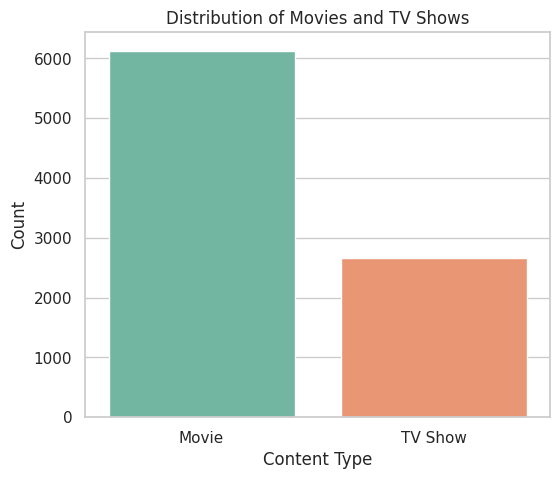

In [43]:
plt.figure(figsize=(6,5))

sns.countplot(data=df, x="type", palette="Set2")

plt.title("Distribution of Movies and TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Count")

plt.show()

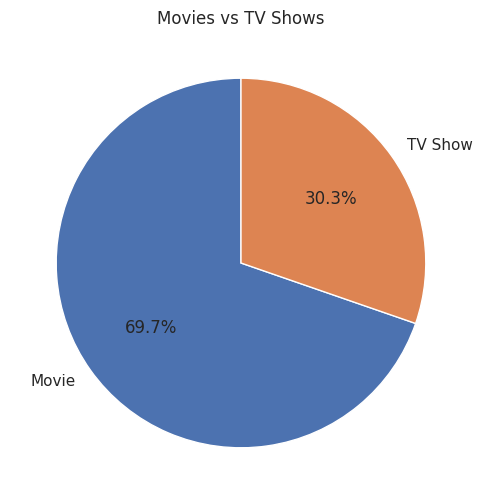

In [44]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Movies vs TV Shows")

plt.show()

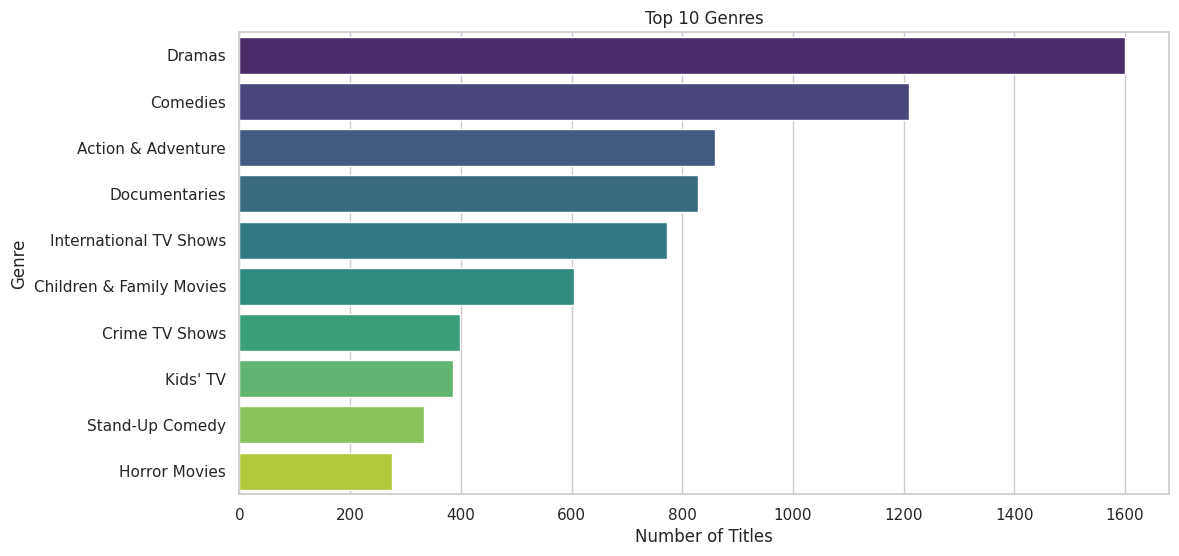

In [45]:
plt.figure(figsize=(12,6))

top_genres = df["primary_genre"].value_counts().head(10)

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    palette="viridis"
)

plt.title("Top 10 Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

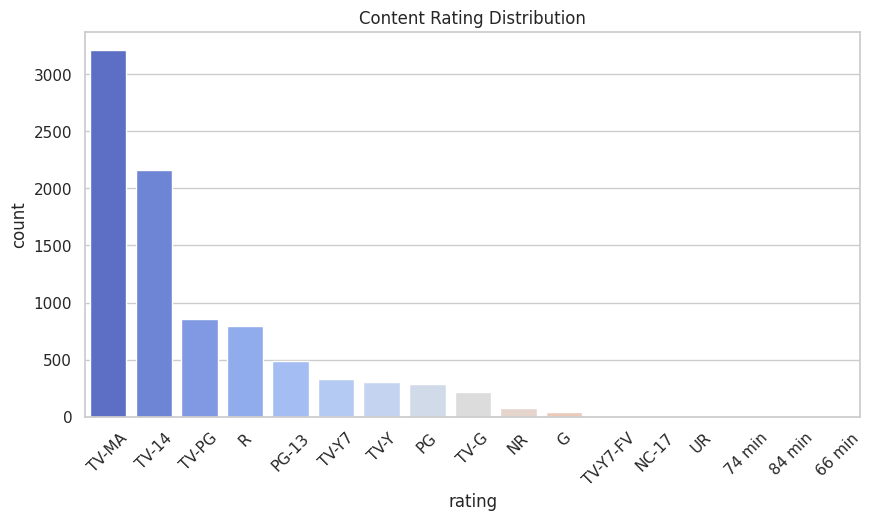

In [46]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="rating",
    order=df["rating"].value_counts().index,
    palette="coolwarm"
)

plt.xticks(rotation=45)

plt.title("Content Rating Distribution")

plt.show()

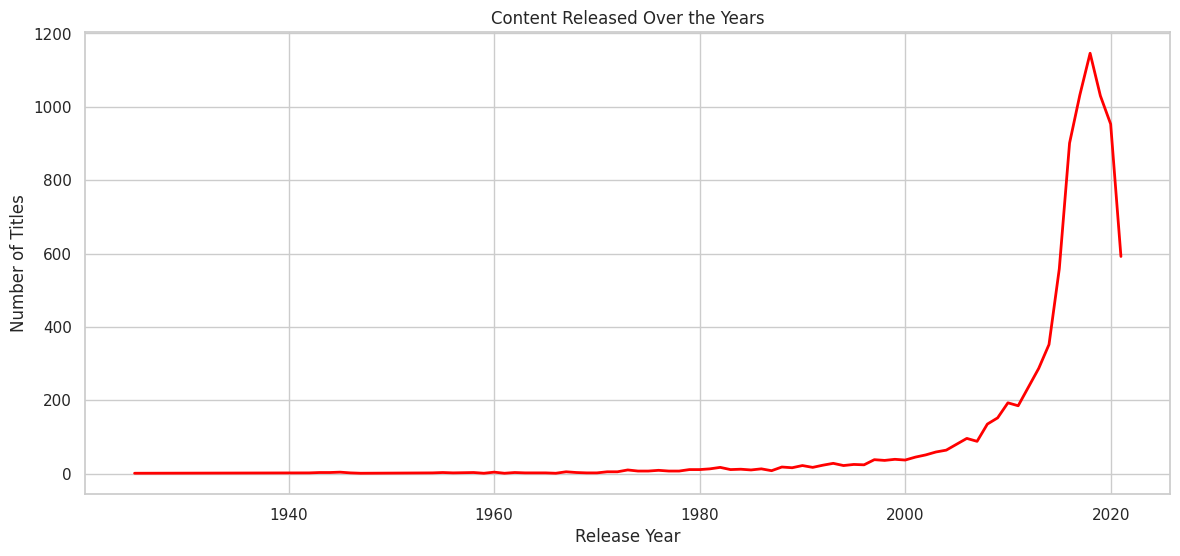

In [47]:
plt.figure(figsize=(14,6))

release = df["release_year"].value_counts().sort_index()

plt.plot(
    release.index,
    release.values,
    color="red",
    linewidth=2
)

plt.title("Content Released Over the Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

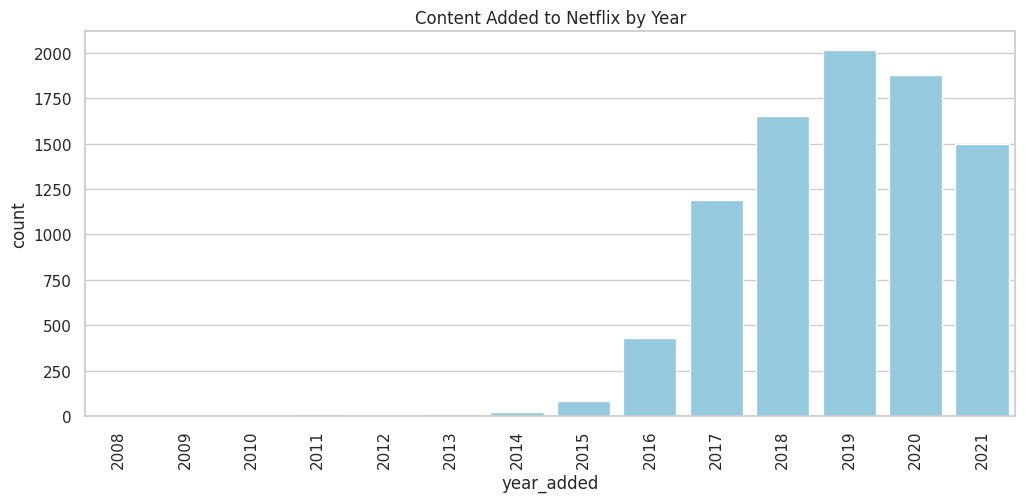

In [48]:
plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x="year_added",
    order=sorted(df["year_added"].dropna().unique()),
    color="skyblue"
)

plt.xticks(rotation=90)

plt.title("Content Added to Netflix by Year")

plt.show()

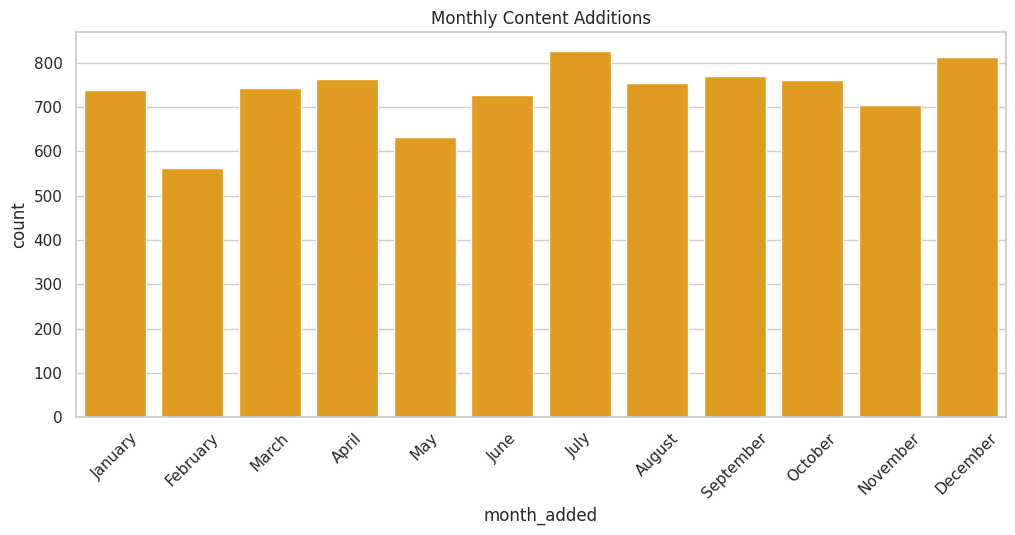

In [49]:
month_order = [
    "January","February","March","April","May","June",
    "July","August","September","October","November","December"
]

plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x="month_added",
    order=month_order,
    color="orange"
)

plt.xticks(rotation=45)

plt.title("Monthly Content Additions")

plt.show()

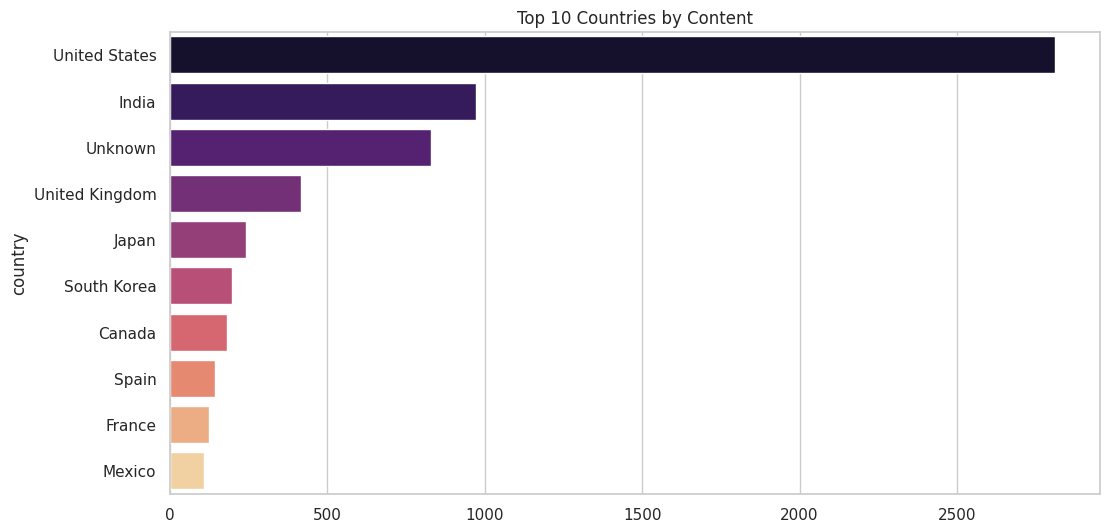

In [50]:
plt.figure(figsize=(12,6))

top_country = df["country"].value_counts().head(10)

sns.barplot(
    x=top_country.values,
    y=top_country.index,
    palette="magma"
)

plt.title("Top 10 Countries by Content")

plt.show()

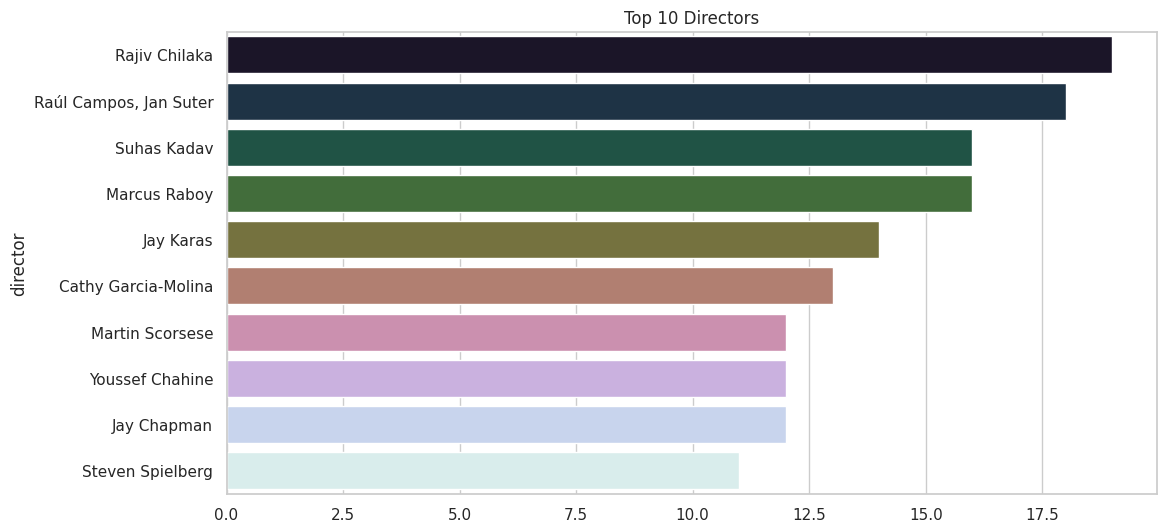

In [51]:
plt.figure(figsize=(12,6))

top_directors = df[df["director"] != "Unknown"]["director"].value_counts().head(10)

sns.barplot(
    x=top_directors.values,
    y=top_directors.index,
    palette="cubehelix"
)

plt.title("Top 10 Directors")

plt.show()

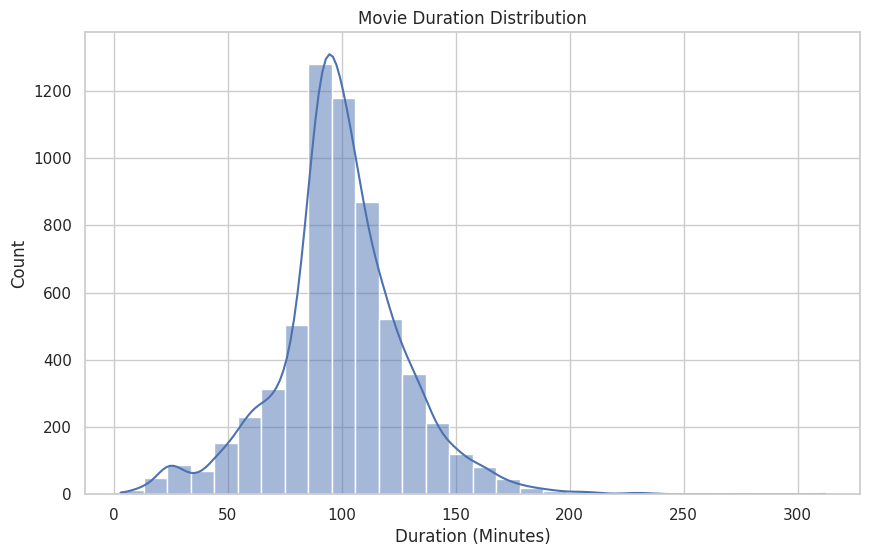

In [52]:
movies = df[df["type"] == "Movie"].copy()

movies["duration_int"] = movies["duration"].str.replace(" min", "", regex=False)

movies["duration_int"] = pd.to_numeric(
    movies["duration_int"],
    errors="coerce"
)

plt.figure(figsize=(10,6))

sns.histplot(
    movies["duration_int"].dropna(),
    bins=30,
    kde=True
)

plt.title("Movie Duration Distribution")

plt.xlabel("Duration (Minutes)")

plt.show()

In [53]:
print("Total Records :", len(df))
print("Movies :", (df["type"]=="Movie").sum())
print("TV Shows :", (df["type"]=="TV Show").sum())

print("\nTop Genre:")
print(df["primary_genre"].value_counts().head())

print("\nTop Rating:")
print(df["rating"].value_counts().head())

print("\nTop Country:")
print(df["country"].value_counts().head())

Total Records : 8797
Movies : 6131
TV Shows : 2666

Top Genre:
primary_genre
Dramas                    1600
Comedies                  1210
Action & Adventure         859
Documentaries              829
International TV Shows     773
Name: count, dtype: int64

Top Rating:
rating
TV-MA    3209
TV-14    2157
TV-PG     861
R         799
PG-13     490
Name: count, dtype: int64

Top Country:
country
United States     2812
India              972
Unknown            830
United Kingdom     418
Japan              244
Name: count, dtype: int64


# Key Observations

- Movies are more numerous than TV Shows.
- Drama and International Movies are among the most common genres.
- TV-MA is one of the most frequent content ratings.
- The number of titles increased significantly after 2015.
- The United States contributes the highest number of titles.
- Most movies have durations between 80 and 120 minutes.
- Netflix added a large amount of content in recent years.

In [54]:
!pip install dash jupyter-dash -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 64.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 95.4 MB/s eta 0:00:00


In [55]:
from dash import Dash, dcc, html
from dash.dependencies import Input, Output

import plotly.express as px

In [56]:
app = Dash(__name__)

In [57]:
total_titles = len(df)
movies = (df["type"] == "Movie").sum()
tvshows = (df["type"] == "TV Show").sum()

app.layout = html.Div([

    html.H1(
        "🎬 Netflix Content Analytics Dashboard",
        style={
            "textAlign": "center",
            "color": "darkred"
        }
    ),

    html.Div([
        html.H3(f"Total Titles: {total_titles}"),
        html.H3(f"Movies: {movies}"),
        html.H3(f"TV Shows: {tvshows}")
    ],
    style={
        "display":"flex",
        "justifyContent":"space-around",
        "padding":"20px"
    }),

    dcc.Dropdown(
        id="content_type",
        options=[
            {"label":"All","value":"All"},
            {"label":"Movie","value":"Movie"},
            {"label":"TV Show","value":"TV Show"}
        ],
        value="All"
    ),

    dcc.Graph(id="genre_chart"),

    dcc.Graph(id="release_chart")

])

In [60]:
@app.callback(
    Output("genre_chart","figure"),
    Output("release_chart","figure"),
    Input("content_type","value")
)

def update_graph(selected):

    if selected=="All":
        filtered=df
    else:
        filtered=df[df["type"]==selected]

    genre=filtered["primary_genre"].value_counts().head(10)

    fig1=px.bar(
        x=genre.index,
        y=genre.values,
        title="Top Genres"
    )

    release=filtered["release_year"].value_counts().sort_index()

    fig2=px.line(
        x=release.index,
        y=release.values,
        title="Release Year Trend"
    )

    return fig1,fig2

In [63]:
print("="*50)
print("NETFLIX DASHBOARD SUMMARY")
print("="*50)

print(f"Total Titles : {len(df)}")
print(f"Movies       : {(df['type']=='Movie').sum()}")
print(f"TV Shows     : {(df['type']=='TV Show').sum()}")
print(f"Countries    : {df['country'].nunique()}")
print(f"Genres       : {df['primary_genre'].nunique()}")

NETFLIX DASHBOARD SUMMARY
Total Titles : 8797
Movies       : 6131
TV Shows     : 2666
Countries    : 749
Genres       : 36


In [64]:
import plotly.express as px

genre = df["primary_genre"].value_counts().head(10)

fig = px.bar(
    x=genre.index,
    y=genre.values,
    title="Top 10 Netflix Genres",
    labels={
        "x":"Genre",
        "y":"Count"
    }
)

fig.show()

In [65]:
release = df["release_year"].value_counts().sort_index()

fig = px.line(
    x=release.index,
    y=release.values,
    markers=True,
    title="Netflix Release Year Trend"
)

fig.show()

In [66]:
rating = df["rating"].value_counts()

fig = px.pie(
    values=rating.values,
    names=rating.index,
    title="Netflix Ratings Distribution"
)

fig.show()

In [67]:
country = df["country"].value_counts().head(10)

fig = px.bar(
    x=country.index,
    y=country.values,
    title="Top Countries"
)

fig.show()

In [69]:
import os

# Create images folder if it doesn't exist
os.makedirs("images", exist_ok=True)

print("✅ Images folder created successfully.")

✅ Images folder created successfully.


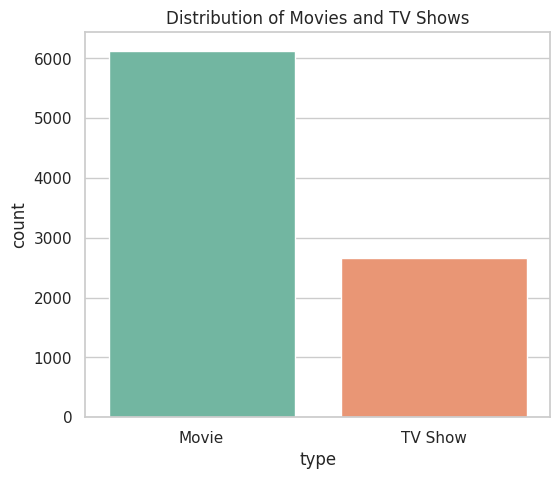

In [70]:
plt.figure(figsize=(6,5))
sns.countplot(data=df, x="type", palette="Set2")
plt.title("Distribution of Movies and TV Shows")

plt.savefig(
    "images/movies_vs_tvshows.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [71]:
import os

os.listdir("images")

['movies_vs_tvshows.png']

In [72]:
import os

folders = [
    "data",
    "images",
    "notebooks",
    "reports",
    "presentation"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("✅ Project folders created successfully!")

✅ Project folders created successfully!


In [73]:
plt.savefig("images/top_genres.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [74]:
df.to_csv("data/cleaned_netflix.csv", index=False)

In [75]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [76]:
import os

base_path = "/content/drive/MyDrive/Netflix-Content-Analytics-Dashboard"

folders = [
    "data",
    "images",
    "notebooks",
    "reports",
    "presentation"
]

for folder in folders:
    os.makedirs(os.path.join(base_path, folder), exist_ok=True)

print("✅ Project folders created in Google Drive!")

✅ Project folders created in Google Drive!


In [77]:
# Save cleaned dataset
df.to_csv(f"{base_path}/data/cleaned_netflix.csv", index=False)

# Save a chart
plt.savefig(f"{base_path}/images/movies_vs_tvshows.png",
            dpi=300,
            bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [78]:
import os

print("Current Folder:", os.getcwd())
print("\nFiles and Folders:")

for item in os.listdir():
    print(item)

Current Folder: /content

Files and Folders:
.config
netflix_titles.csv
drive
netflix_titles (1).csv
data
reports
notebooks
presentation
images
sample_data


In [79]:
import os

print("Data folder:")
print(os.listdir("data"))

print("\nImages folder:")
print(os.listdir("images"))

Data folder:
['cleaned_netflix.csv']

Images folder:
['top_genres.png', 'movies_vs_tvshows.png']
